# Where Are Drivers Coming From? A Crossing-by-Crossing Look at Congestion Pricing
**Data with Mehreen · Week 3: The 12 doors into the zone**

Every vehicle that enters Manhattan's Congestion Relief Zone is first detected at one of **12 crossings**: tunnels from New Jersey, tunnels and bridges over the East River, and the streets and highways that cross 60th Street from the north.

Weeks 1 and 2 looked at the zone as a whole. This week we open the 12 doors one by one.

### Why crossings matter: tolls and credits
- **Tolled tunnels** (Lincoln, Holland, Queens-Midtown, Hugh L. Carey): drivers who already paid a tunnel toll get a **crossing credit** that reduces the congestion toll during peak hours.
- **Free East River bridges** (Brooklyn, Manhattan, Williamsburg, Queensboro): no bridge toll, so **no credit**. These drivers pay the full congestion toll.
- **60th Street crossings** (East 60th St, West 60th St, FDR Drive, West Side Highway): traffic coming down from upper Manhattan, the Bronx and beyond.

### Questions for Week 3
1. Which crossings carry the most traffic, and which lost the most from 2025 to 2026?
2. Did free bridges and tolled tunnels change differently?
3. Who uses each crossing: private cars, taxis/Uber/Lyft, trucks?
4. What does a day look like at each crossing, hour by hour?
5. Where is toll-timing (the 5am cliff from Week 2) strongest?
6. **A reader's question:** is East 60th Street busy because of the toll-free Queensboro Bridge next to it?

## 1. Setup

In [1]:
from pathlib import Path
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch

pd.set_option("display.width", 140)
plt.rcParams.update({
    "figure.figsize": (11, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})
SOURCE = "Source: MTA Open Data · Data with Mehreen"
def add_source(fig):
    fig.text(0.99, 0.005, SOURCE, ha="right", fontsize=8, color="gray")

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
API_URL = "https://data.ny.gov/resource/t6yz-b64h.json"

CAR, TAXI = "Cars/Pickups/Vans", "Taxi / Uber / Lyft"
VEHICLE_LABELS = {
    "1 - Cars, Pickups and Vans": CAR,
    "2 - Single-Unit Trucks": "Trucks",
    "3 - Multi-Unit Trucks": "Trucks",
    "4 - Buses": "Buses & motorcycles",
    "5 - Motorcycles": "Buses & motorcycles",
    "TLC Taxi/FHV": TAXI,
}
VEHICLE_COLORS = {CAR: "#1f4e79", TAXI: "#8e44ad", "Trucks": "#e07b39", "Buses & motorcycles": "#b0b7c3"}

# The 12 crossings, grouped by how drivers pay
CROSSING_TYPE = {
    "Lincoln Tunnel": "NJ tunnels (tolled)",
    "Holland Tunnel": "NJ tunnels (tolled)",
    "Queens Midtown Tunnel": "East River tunnels (tolled)",
    "Hugh L. Carey Tunnel": "East River tunnels (tolled)",
    "Brooklyn Bridge": "East River bridges (free)",
    "Manhattan Bridge": "East River bridges (free)",
    "Williamsburg Bridge": "East River bridges (free)",
    "Queensboro Bridge": "East River bridges (free)",
    "East 60th St": "60th St crossings",
    "West 60th St": "60th St crossings",
    "FDR Drive at 60th St": "60th St crossings",
    "West Side Highway at 60th St": "60th St crossings",
}
TYPE_COLORS = {
    "NJ tunnels (tolled)": "#1f4e79",
    "East River tunnels (tolled)": "#5b8fc7",
    "East River bridges (free)": "#e07b39",
    "60th St crossings": "#2e8b57",
}
type_legend = [Patch(color=c, label=t) for t, c in TYPE_COLORS.items()]

## 2. Get the data
The same helper as Weeks 1 and 2. `daily_by_crossing` is already cached from Week 1; two small new tables are downloaded once.

In [2]:
def fetch_soql(select, group, order, name, where=None, page_size=50_000):
    """Run an aggregated SoQL query (with paging) and cache the result as CSV."""
    cache = DATA_DIR / f"{name}.csv"
    if cache.exists():
        print(f"Loaded cached {cache}")
        return pd.read_csv(cache)

    rows, offset = [], 0
    while True:
        params = {"$select": select, "$group": group, "$order": order,
                  "$limit": page_size, "$offset": offset}
        if where:
            params["$where"] = where
        r = requests.get(API_URL, params=params, timeout=180)
        r.raise_for_status()
        batch = r.json()
        rows.extend(batch)
        print(f"  {name}: fetched {len(rows):,} rows")
        if len(batch) < page_size:
            break
        offset += page_size

    df = pd.DataFrame(rows)
    df.to_csv(cache, index=False)
    return df

| Table | Grouped by | Approx. rows | Used for |
|---|---|---|---|
| `daily_by_crossing` (Week 1) | date × crossing | ~8,000 | volumes and 2025 vs 2026 changes |
| `crossing_vehicle_daily` | date × crossing × vehicle class | ~50,000 | who uses each crossing, and how that changed |
| `crossing_hourly` | year × day of week × hour × crossing × vehicle class | ~24,000 | hour-by-hour patterns |
| `crossing_boundaries` | year × day of week × 10-min block × crossing × vehicle class, only the blocks around 5am, 9am and 9pm | ~12,000 | the toll-switch "cliffs" per crossing |

In [3]:
daily_by_crossing = fetch_soql(
    select="toll_date, detection_group, detection_region, sum(crz_entries) AS entries",
    group="toll_date, detection_group, detection_region",
    order="toll_date, detection_group",
    name="daily_by_crossing",
)

crossing_vehicle_daily = fetch_soql(
    select="toll_date, detection_group, vehicle_class, sum(crz_entries) AS entries",
    group="toll_date, detection_group, vehicle_class",
    order="toll_date, detection_group, vehicle_class",
    name="crossing_vehicle_daily",
)

crossing_hourly = fetch_soql(
    select=("date_extract_y(toll_date) AS year, day_of_week_int, hour_of_day, "
            "detection_group, vehicle_class, sum(crz_entries) AS entries"),
    group="date_extract_y(toll_date), day_of_week_int, hour_of_day, detection_group, vehicle_class",
    order="year, day_of_week_int, hour_of_day, detection_group, vehicle_class",
    name="crossing_hourly",
)

crossing_boundaries = fetch_soql(
    select=("date_extract_y(toll_date) AS year, day_of_week_int, hour_of_day, minute_of_hour, "
            "detection_group, vehicle_class, sum(crz_entries) AS entries"),
    where="hour_of_day in (4, 5, 8, 9, 20, 21) AND minute_of_hour in (0, 50)",
    group="date_extract_y(toll_date), day_of_week_int, hour_of_day, minute_of_hour, detection_group, vehicle_class",
    order="year, day_of_week_int, hour_of_day, minute_of_hour, detection_group, vehicle_class",
    name="crossing_boundaries",
)
crossing_vehicle_daily.head()

Loaded cached data/daily_by_crossing.csv
Loaded cached data/crossing_vehicle_daily.csv
Loaded cached data/crossing_hourly.csv
Loaded cached data/crossing_boundaries.csv


,toll_date,detection_group,vehicle_class,entries
0,2025-01-05T00:00:00.000,Brooklyn Bridge,"1 - Cars, Pickups and Vans",16519
1,2025-01-05T00:00:00.000,Brooklyn Bridge,2 - Single-Unit Trucks,108
2,2025-01-05T00:00:00.000,Brooklyn Bridge,3 - Multi-Unit Trucks,3
3,2025-01-05T00:00:00.000,Brooklyn Bridge,4 - Buses,11
4,2025-01-05T00:00:00.000,Brooklyn Bridge,5 - Motorcycles,29


## 3. Clean
Same rules as before: real dates and numbers, the last incomplete week dropped, storm days removed from the daily tables, and every crossing tagged with its type.

In [4]:
STORM_DAYS = pd.to_datetime(["2026-01-25", "2026-01-26", "2026-02-22", "2026-02-23", "2026-02-24"])

def clean_daily(df):
    df = df.copy()
    df["toll_date"] = pd.to_datetime(df["toll_date"]).dt.tz_localize(None)
    df["entries"] = pd.to_numeric(df["entries"])
    df["crossing_type"] = df["detection_group"].map(CROSSING_TYPE)
    if "vehicle_class" in df:
        df["vehicle"] = df["vehicle_class"].map(VEHICLE_LABELS).fillna(df["vehicle_class"])
    return df

daily_by_crossing = clean_daily(daily_by_crossing)
crossing_vehicle_daily = clean_daily(crossing_vehicle_daily)

# Keep complete weeks only (weeks run Sunday to Saturday), the same cutoff for both tables
last_date = min(daily_by_crossing["toll_date"].max(), crossing_vehicle_daily["toll_date"].max())
cutoff = last_date - pd.Timedelta(days=(last_date.dayofweek - 5) % 7)
daily_by_crossing = daily_by_crossing[(daily_by_crossing["toll_date"] <= cutoff)
                                      & ~daily_by_crossing["toll_date"].isin(STORM_DAYS)]
crossing_vehicle_daily = crossing_vehicle_daily[(crossing_vehicle_daily["toll_date"] <= cutoff)
                                                & ~crossing_vehicle_daily["toll_date"].isin(STORM_DAYS)]

# Same dates in both years, for fair 2025 vs 2026 comparisons
def same_dates(df):
    mmdd = df["toll_date"].dt.strftime("%m-%d")
    out = df[mmdd.between("01-05", "10-31")].copy()
    out["year"] = out["toll_date"].dt.year
    return out

# Hourly and boundary tables: add day type, crossing type and the number of days behind each total
all_days = pd.DataFrame({"date": pd.date_range("2025-01-05", last_date)})
all_days["year"] = all_days["date"].dt.year
all_days["day_of_week_int"] = (all_days["date"].dt.dayofweek + 1) % 7 + 1   # Sunday = 1 ... Saturday = 7
n_days = all_days.groupby(["year", "day_of_week_int"]).size().rename("n_days").reset_index()

def clean_grouped(df):
    df = df.copy()
    for col in ["year", "day_of_week_int", "hour_of_day", "entries"] + (["minute_of_hour"] if "minute_of_hour" in df else []):
        df[col] = pd.to_numeric(df[col])
    df["vehicle"] = df["vehicle_class"].map(VEHICLE_LABELS).fillna(df["vehicle_class"])
    df["crossing_type"] = df["detection_group"].map(CROSSING_TYPE)
    df["day_type"] = np.where(df["day_of_week_int"].isin([1, 7]), "Weekend", "Weekday")
    return df.merge(n_days, on=["year", "day_of_week_int"], how="left")

crossing_hourly = clean_grouped(crossing_hourly)
crossing_boundaries = clean_grouped(crossing_boundaries)

print("Daily tables:", daily_by_crossing["toll_date"].min().date(), "to", cutoff.date())
print("Crossings:", daily_by_crossing["detection_group"].nunique())
assert daily_by_crossing["crossing_type"].notna().all(), 'A crossing is missing from CROSSING_TYPE'

Daily tables: 2025-01-05 to 2026-11-07
Crossings: 12


## 4. Analysis
### Q1a: Which crossings carry the most traffic?

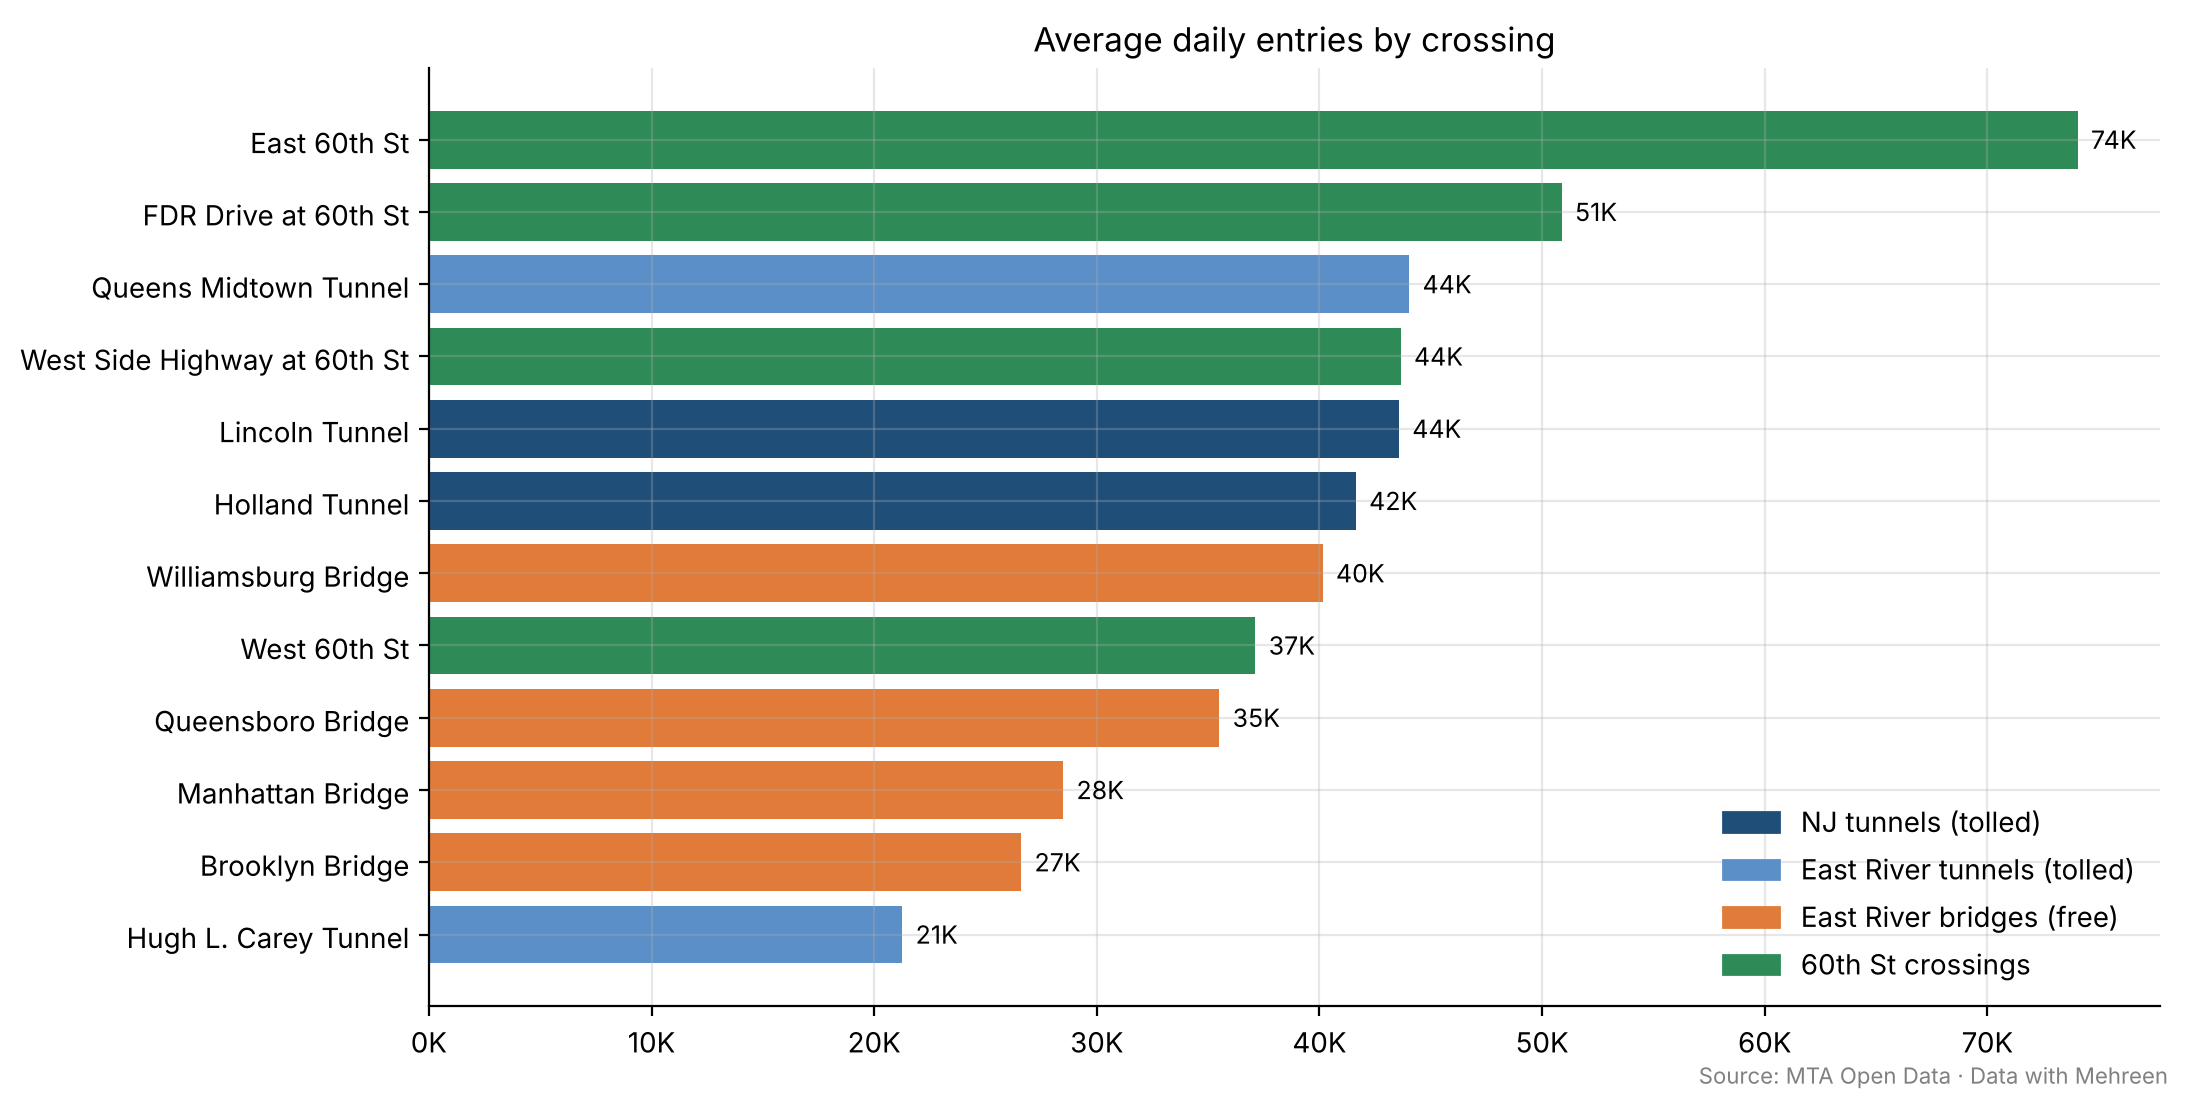

crossing_type
60th St crossings              42.2
East River bridges (free)      26.8
NJ tunnels (tolled)            17.5
East River tunnels (tolled)    13.4
Name: share_of_entries_%, dtype: float64

In [5]:
n_dates = daily_by_crossing["toll_date"].nunique()
volume = (daily_by_crossing.groupby("detection_group")["entries"].sum() / n_dates).sort_values()

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.barh(volume.index, volume.values, color=[TYPE_COLORS[CROSSING_TYPE[c]] for c in volume.index])
for i, v in enumerate(volume.values):
    ax.text(v + 600, i, f"{v/1000:.0f}K", va="center", fontsize=9)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))
ax.set_title("Average daily entries by crossing")
ax.legend(handles=type_legend, frameon=False, loc="lower right")
add_source(fig); plt.tight_layout(); plt.show()

by_type = (daily_by_crossing.groupby("crossing_type")["entries"].sum() / n_dates)
(by_type / by_type.sum() * 100).round(1).sort_values(ascending=False).rename("share_of_entries_%")

### Q1b: Which crossings lost the most traffic?
Same dates in both years (January 5 to October 31), storm days removed.

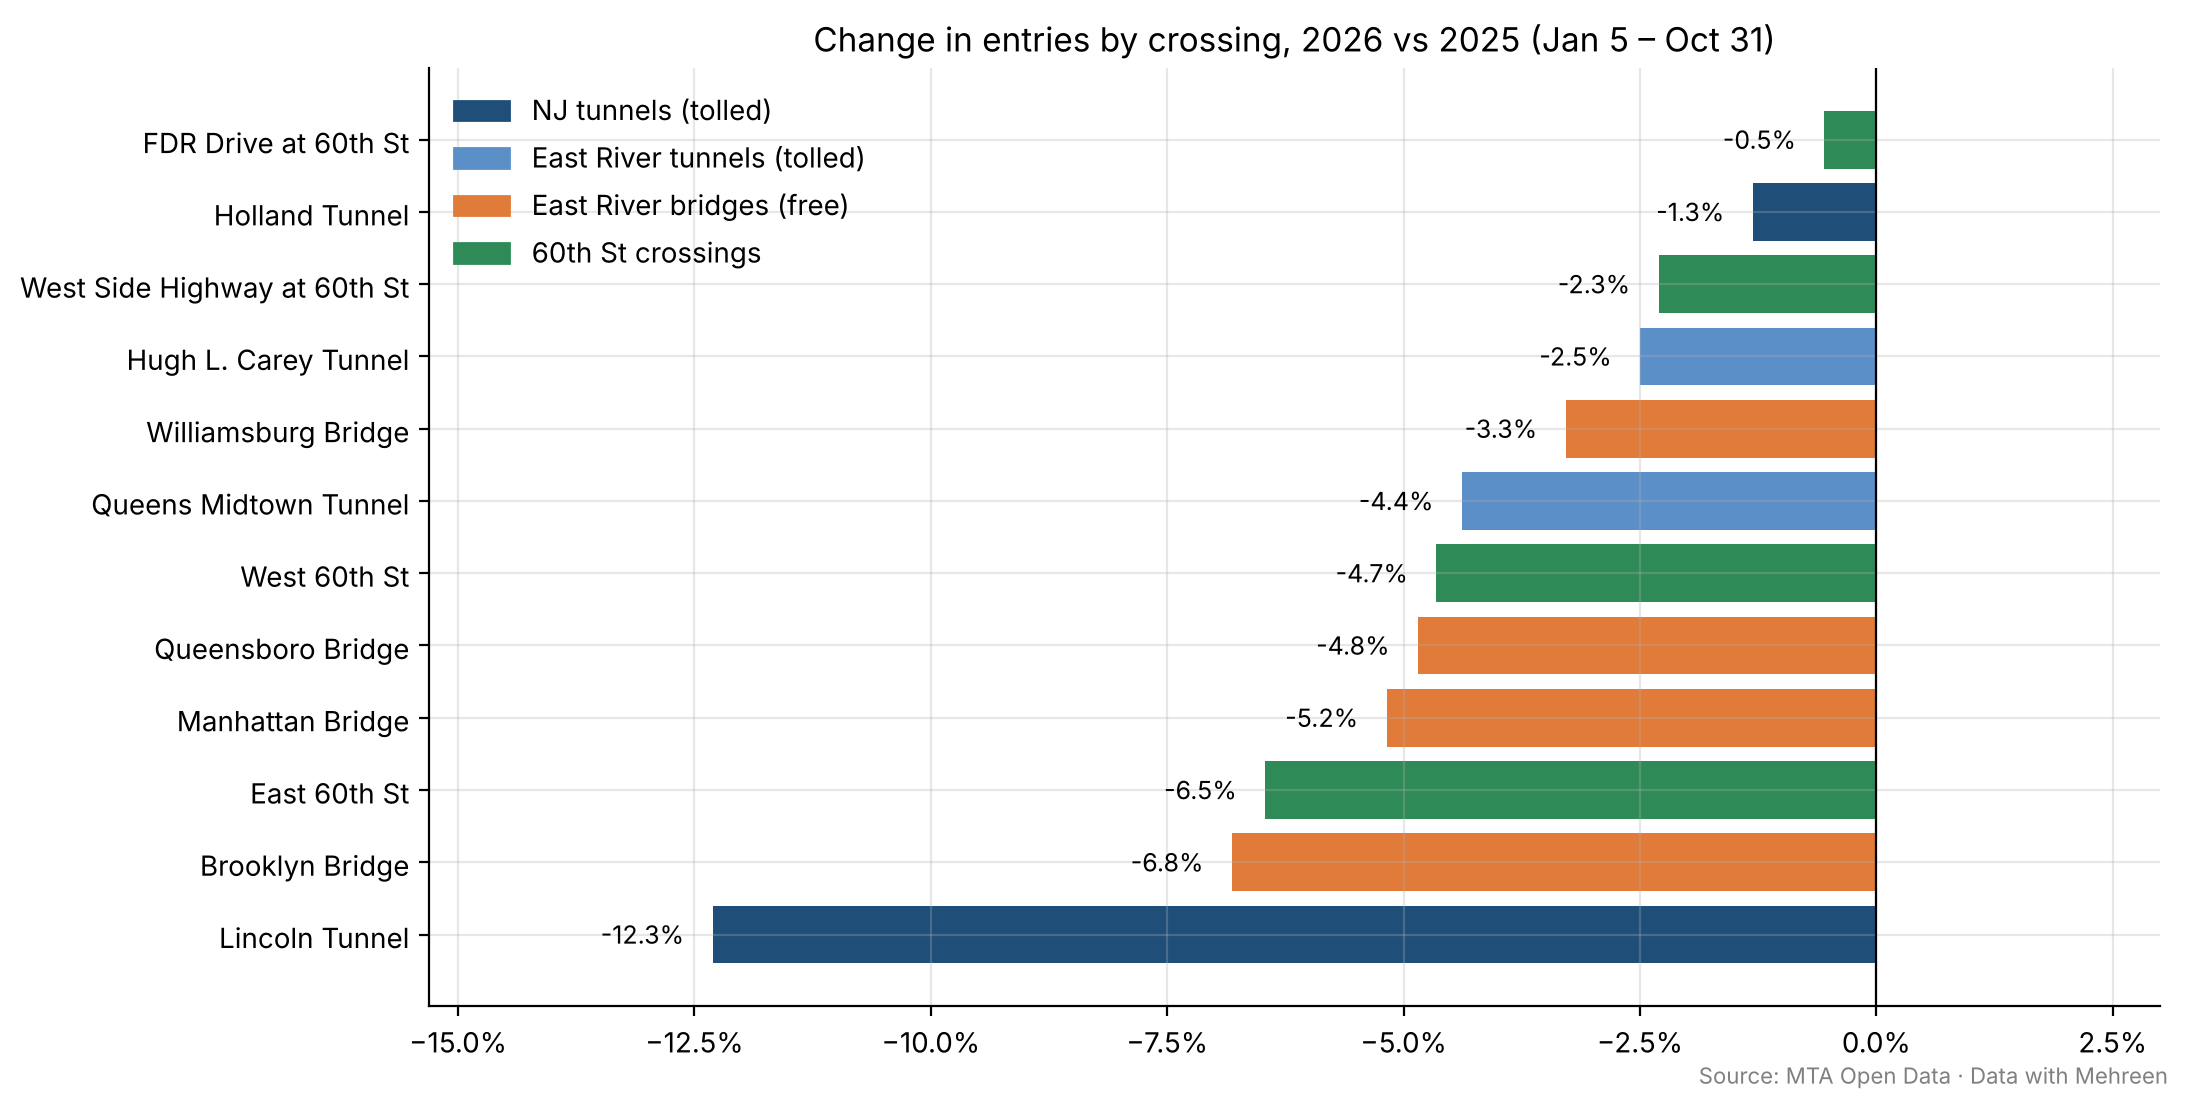

year,2025,2026,change_%,type
detection_group,,,,
Lincoln Tunnel,13827148,12125219,-12.3,NJ tunnels (tolled)
Brooklyn Bridge,8205099,7645876,-6.8,East River bridges (free)
East 60th St,22796897,21323406,-6.5,60th St crossings
Manhattan Bridge,8693031,8242763,-5.2,East River bridges (free)
Queensboro Bridge,10876336,10349108,-4.8,East River bridges (free)
West 60th St,11252914,10729217,-4.7,60th St crossings
Queens Midtown Tunnel,13438743,12849728,-4.4,East River tunnels (tolled)
Williamsburg Bridge,12152027,11752708,-3.3,East River bridges (free)
Hugh L. Carey Tunnel,6378084,6218751,-2.5,East River tunnels (tolled)


In [6]:
sd = same_dates(daily_by_crossing)
change = sd.groupby(["detection_group", "year"])["entries"].sum().unstack()
change["change_%"] = (change[2026] / change[2025] - 1) * 100
change["type"] = change.index.map(CROSSING_TYPE)
change = change.sort_values("change_%")

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.barh(change.index, change["change_%"], color=[TYPE_COLORS[t] for t in change["type"]])
for i, v in enumerate(change["change_%"]):
    ax.text(v + (0.3 if v >= 0 else -0.3), i, f"{v:+.1f}%", va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.axvline(0, color="black", lw=0.8)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlim(change["change_%"].min() - 3, max(change["change_%"].max(), 0) + 3)
ax.set_title("Change in entries by crossing, 2026 vs 2025 (Jan 5 – Oct 31)")
ax.legend(handles=type_legend, frameon=False, loc="upper left")
add_source(fig); plt.tight_layout(); plt.show()
change[[2025, 2026, "change_%", "type"]].round(1)

### Q2: Free bridges vs. tolled tunnels
If the crossing credit matters, tunnel drivers (who get a credit) might hold up better than bridge drivers (who pay the full toll). Or the opposite: tunnel drivers pay **two** tolls in total, so they may have more reason to switch to transit.

Below: the yearly change for each crossing type, then the month-by-month change to check it isn't one odd month.

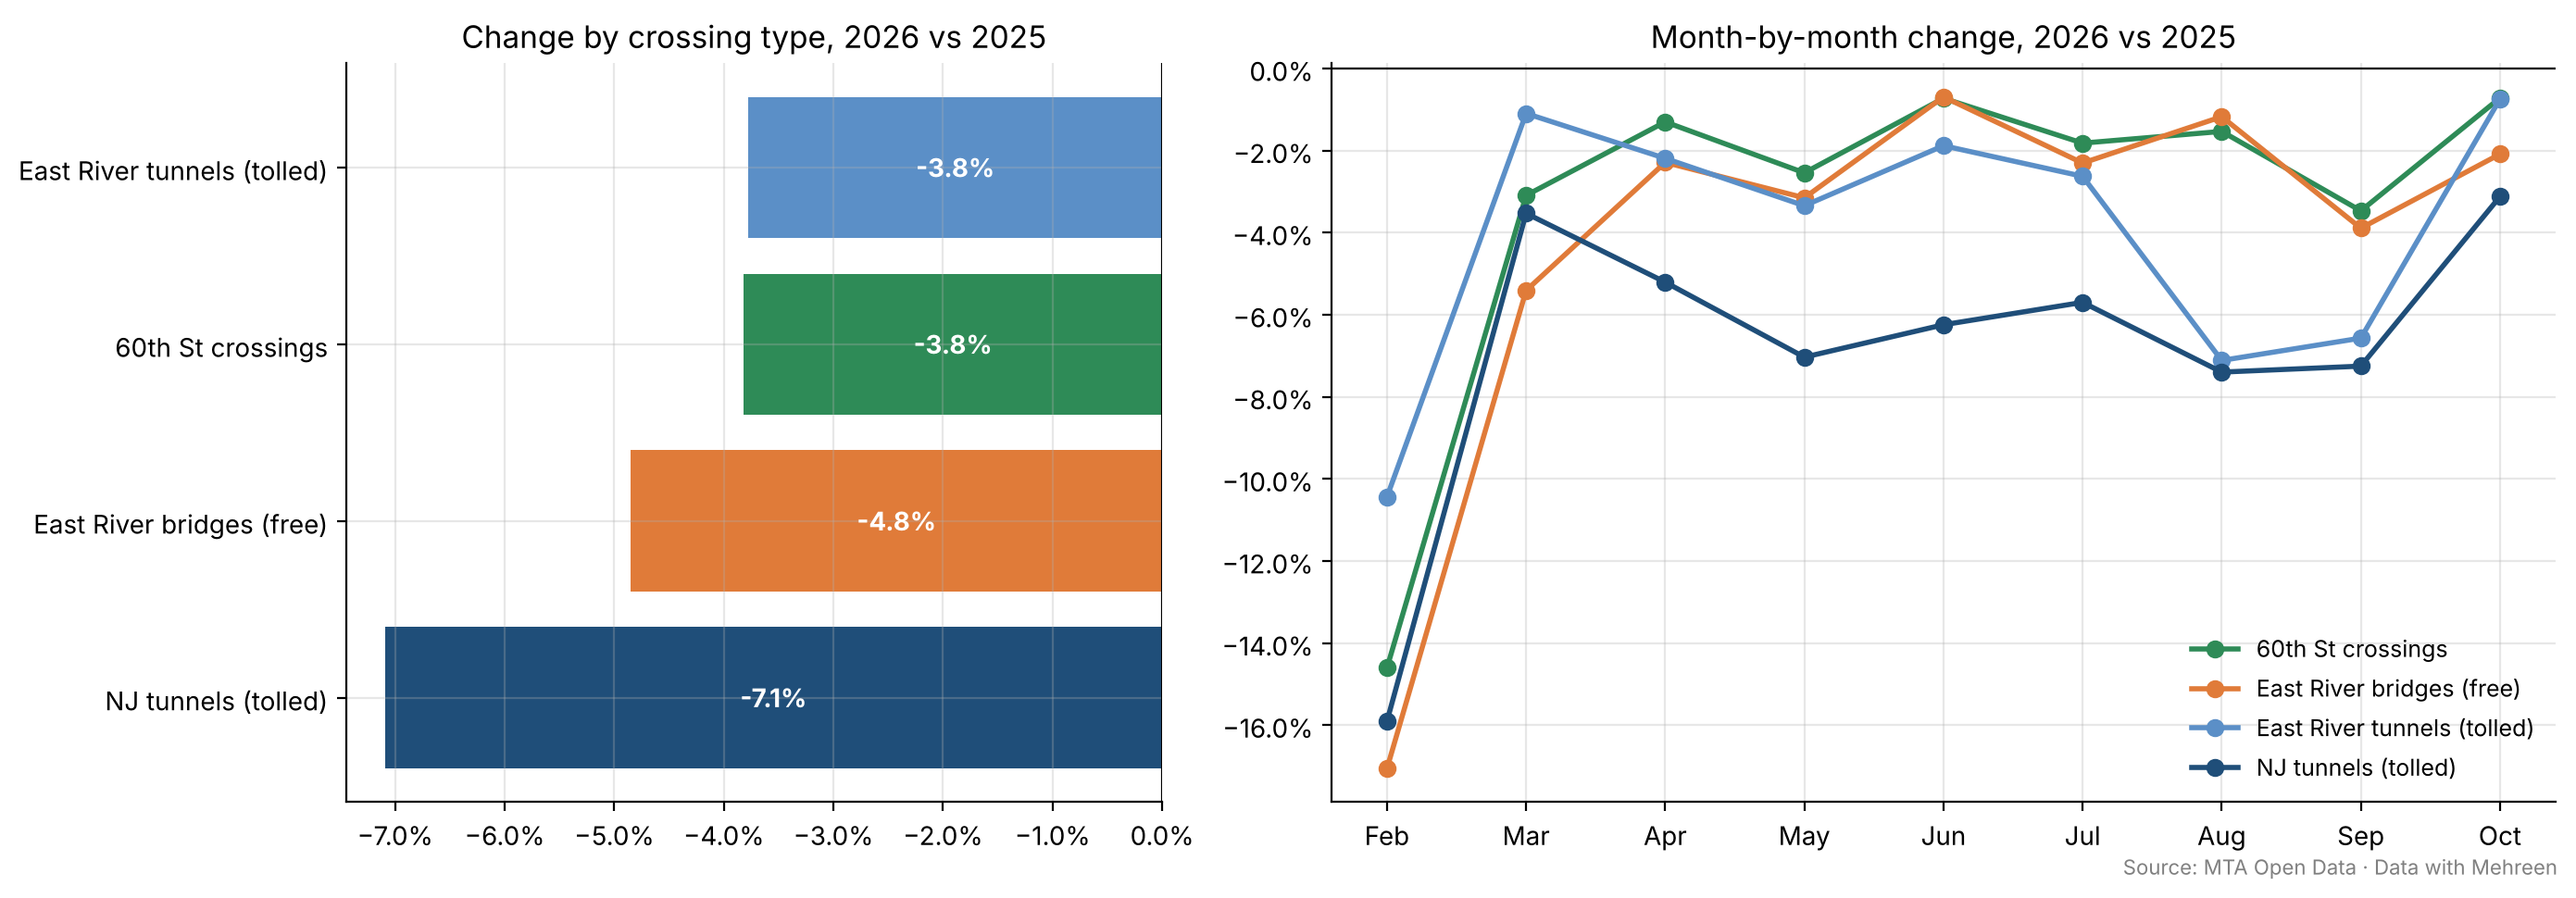

year,2025,2026,change_%
crossing_type,,,
NJ tunnels (tolled),26284655,24419897,-7.1
East River bridges (free),39926493,37990455,-4.8
60th St crossings,62418401,60034715,-3.8
East River tunnels (tolled),19816827,19068479,-3.8


In [7]:
type_change = sd.groupby(["crossing_type", "year"])["entries"].sum().unstack()
type_change["change_%"] = (type_change[2026] / type_change[2025] - 1) * 100
type_change = type_change.sort_values("change_%")

# Month-by-month change by type (full months only: Feb–Oct)
m = sd.assign(month=sd["toll_date"].dt.month)
m = m[m["month"].between(2, 10)]
monthly = m.groupby(["crossing_type", "month", "year"])["entries"].sum().unstack("year")
monthly["change_%"] = (monthly[2026] / monthly[2025] - 1) * 100
monthly = monthly["change_%"].unstack("crossing_type")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.5]})
ax = axes[0]
ax.barh(type_change.index, type_change["change_%"], color=[TYPE_COLORS[t] for t in type_change.index])
for i, v in enumerate(type_change["change_%"]):
    ax.text(v / 2, i, f"{v:+.1f}%", va="center", ha="center", fontsize=10, color="white", fontweight="bold")
ax.axvline(0, color="black", lw=0.8)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("Change by crossing type, 2026 vs 2025")

ax = axes[1]
for t in monthly.columns:
    ax.plot(monthly.index, monthly[t], marker="o", lw=2, color=TYPE_COLORS[t], label=t)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(range(2, 11))
ax.set_xticklabels(["Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct"])
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("Month-by-month change, 2026 vs 2025")
ax.legend(frameon=False, fontsize=9)
add_source(fig); plt.tight_layout(); plt.show()
type_change.round(1)

### Q3a: Who uses each crossing?
The share of each crossing's entries by vehicle type. Ride-hail and taxis tend to be city trips; private cars and trucks often come from farther away.

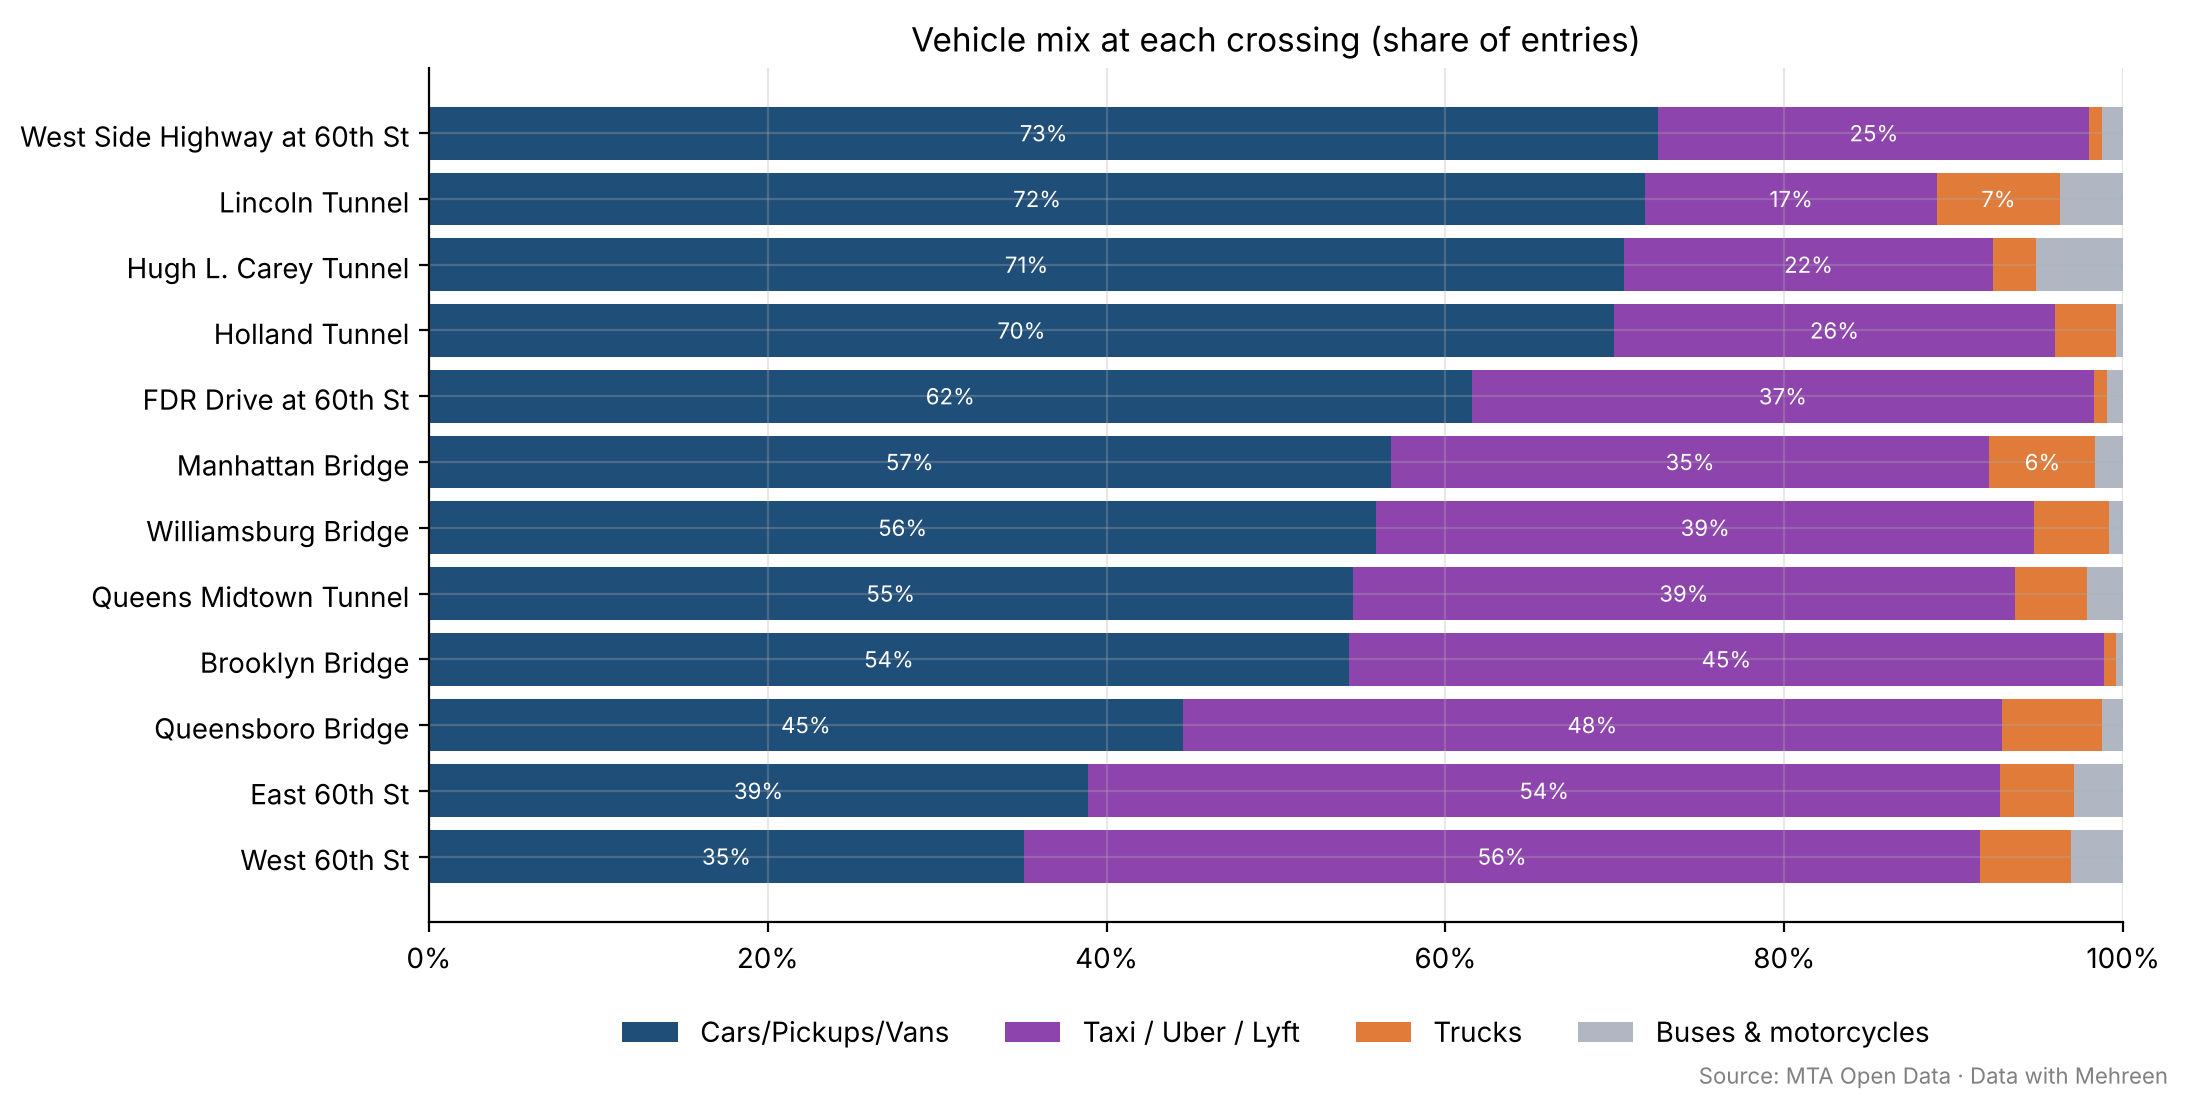

vehicle,Cars/Pickups/Vans,Taxi / Uber / Lyft,Trucks,Buses & motorcycles
detection_group,,,,
West 60th St,35.1,56.4,5.4,3.1
East 60th St,38.9,53.8,4.4,2.9
Queensboro Bridge,44.5,48.3,5.9,1.2
Brooklyn Bridge,54.3,44.6,0.7,0.4
Queens Midtown Tunnel,54.5,39.1,4.3,2.1
Williamsburg Bridge,55.9,38.8,4.4,0.8
Manhattan Bridge,56.8,35.3,6.3,1.6
FDR Drive at 60th St,61.6,36.7,0.8,0.9
Holland Tunnel,69.9,26.0,3.6,0.4


In [8]:
mix = crossing_vehicle_daily.pivot_table(index="detection_group", columns="vehicle", values="entries", aggfunc="sum")
mix = mix.div(mix.sum(axis=1), axis=0) * 100
mix = mix[[CAR, TAXI, "Trucks", "Buses & motorcycles"]].sort_values(CAR)

fig, ax = plt.subplots(figsize=(11, 5.5))
left = np.zeros(len(mix))
for v in mix.columns:
    ax.barh(mix.index, mix[v], left=left, color=VEHICLE_COLORS[v], label=v)
    for i, (l, w) in enumerate(zip(left, mix[v])):
        if w >= 6:
            ax.text(l + w / 2, i, f"{w:.0f}%", va="center", ha="center", fontsize=8, color="white")
    left += mix[v].values
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("Vehicle mix at each crossing (share of entries)")
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.08))
add_source(fig); plt.tight_layout(); plt.show()
mix.round(1)

### Q3b: Where did private cars fall, and where did ride-hail grow?
Week 1 showed private cars −7.3% and taxis/Uber/Lyft +1.6% overall. Here is the same comparison **per crossing**.

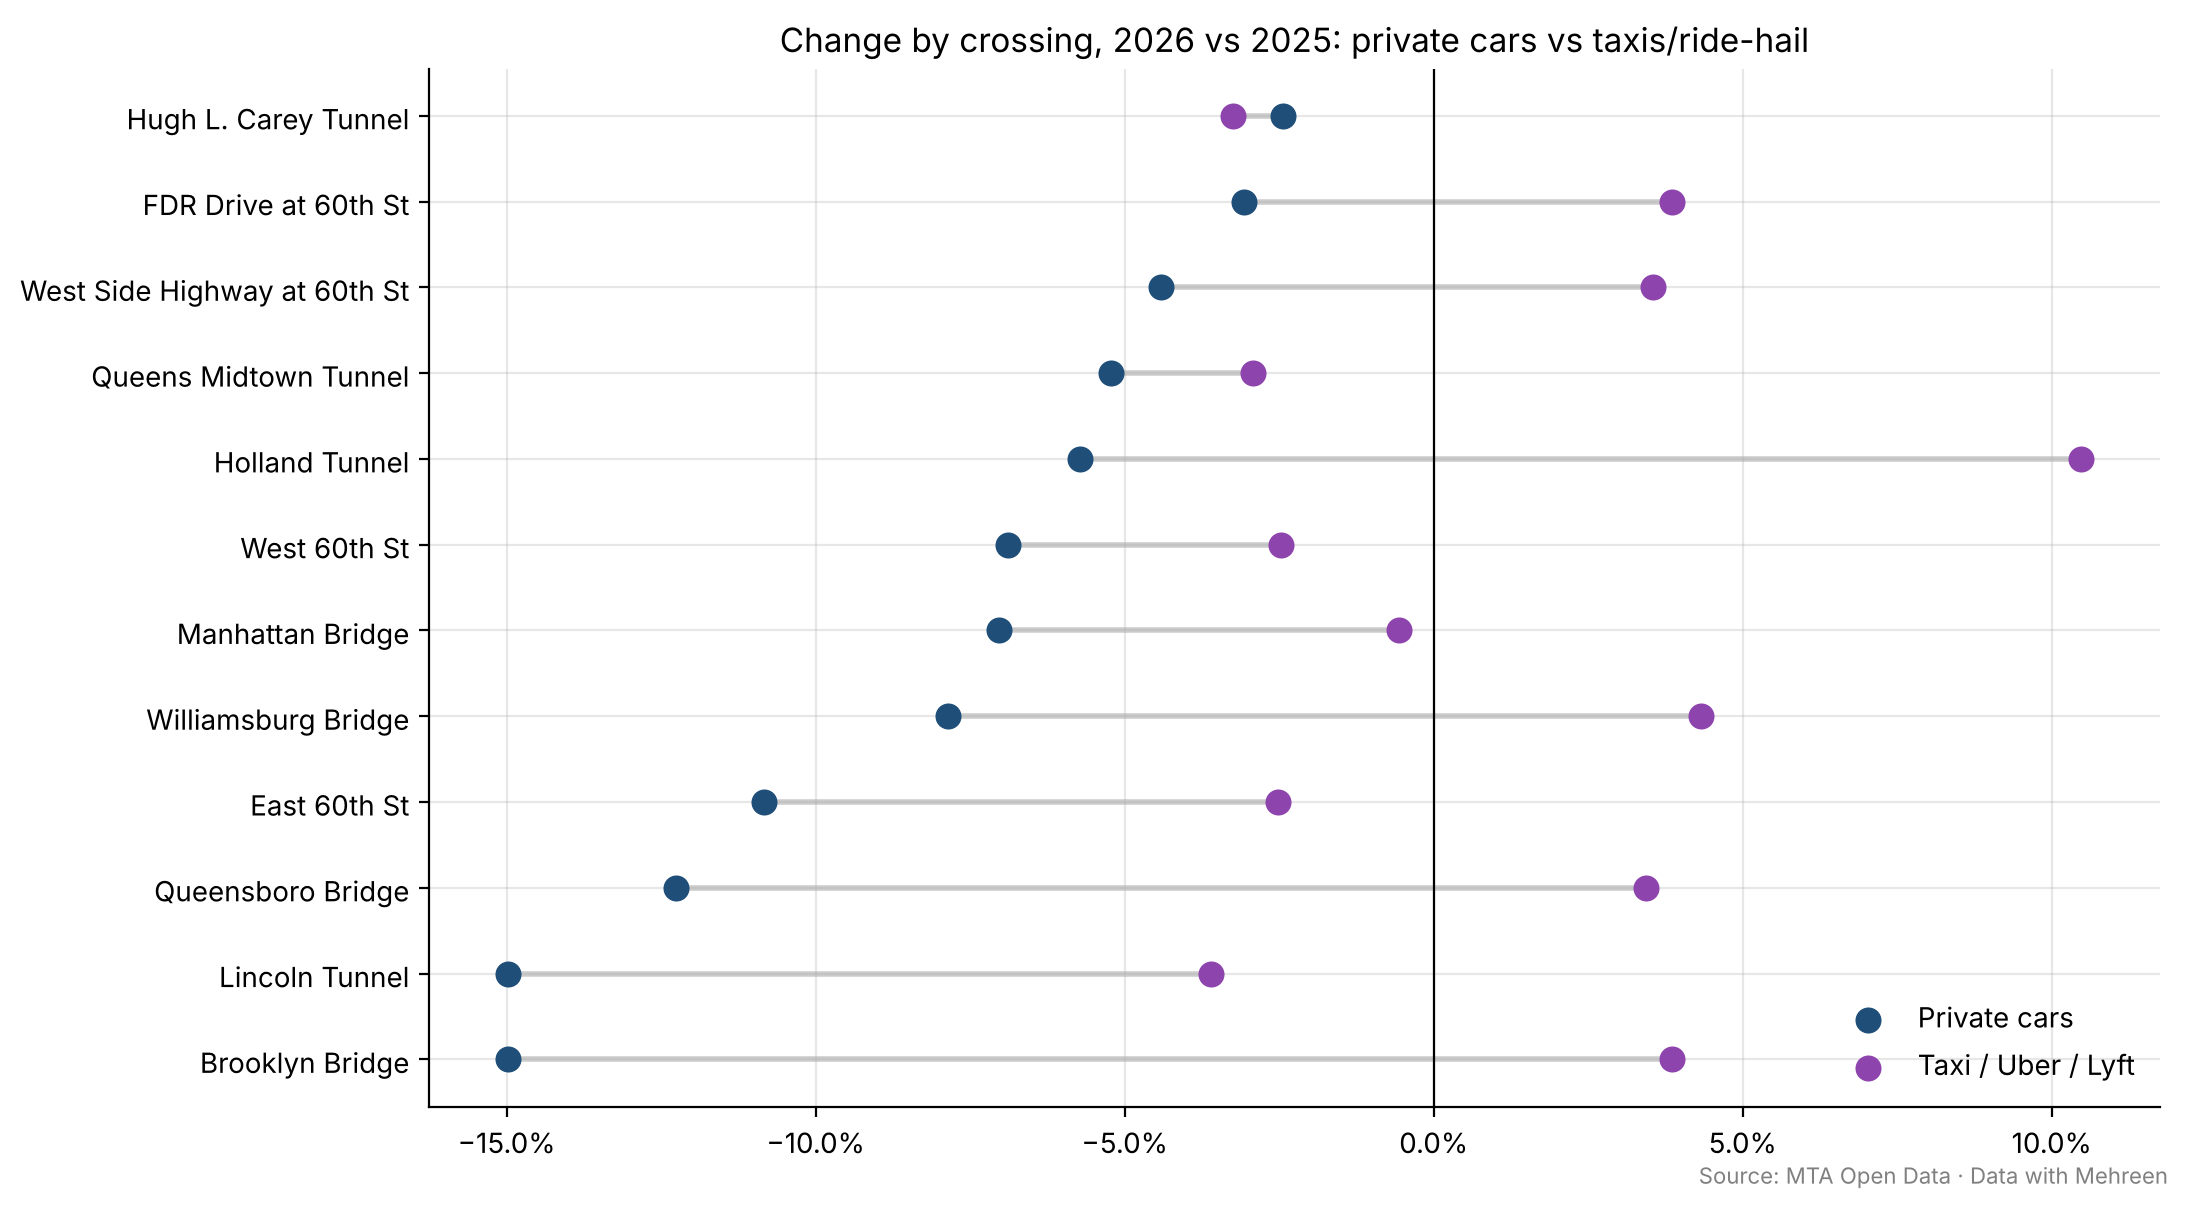

vehicle,Cars/Pickups/Vans,Taxi / Uber / Lyft
detection_group,,
Brooklyn Bridge,-15.0,3.9
Lincoln Tunnel,-15.0,-3.6
Queensboro Bridge,-12.3,3.4
East 60th St,-10.8,-2.5
Williamsburg Bridge,-7.9,4.3
Manhattan Bridge,-7.0,-0.6
West 60th St,-6.9,-2.5
Holland Tunnel,-5.7,10.5
Queens Midtown Tunnel,-5.2,-2.9


In [9]:
sdv = same_dates(crossing_vehicle_daily)
cv = sdv[sdv["vehicle"].isin([CAR, TAXI])].groupby(["detection_group", "vehicle", "year"])["entries"].sum().unstack("year")
cv["change_%"] = (cv[2026] / cv[2025] - 1) * 100
cv = cv["change_%"].unstack("vehicle").sort_values(CAR)

fig, ax = plt.subplots(figsize=(11, 6))
y = np.arange(len(cv))
for i, (a, b) in enumerate(zip(cv[CAR], cv[TAXI])):
    ax.plot([a, b], [i, i], color="#cccccc", lw=2, zorder=1)
ax.scatter(cv[CAR], y, color=VEHICLE_COLORS[CAR], s=70, label="Private cars", zorder=2)
ax.scatter(cv[TAXI], y, color=VEHICLE_COLORS[TAXI], s=70, label="Taxi / Uber / Lyft", zorder=2)
ax.set_yticks(y); ax.set_yticklabels(cv.index)
ax.axvline(0, color="black", lw=0.8)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("Change by crossing, 2026 vs 2025: private cars vs taxis/ride-hail")
ax.legend(frameon=False, loc="lower right")
add_source(fig); plt.tight_layout(); plt.show()
cv.round(1)

### Q4: What does a weekday look like at each crossing?
A heatmap of **private car** entries on weekdays: each row is a crossing, each column an hour, and the color is that hour's share of the crossing's daily entries. Rows are sorted by when their morning peak happens.

Look for crossings that come alive early (long-distance commuters) vs. late (city trips).

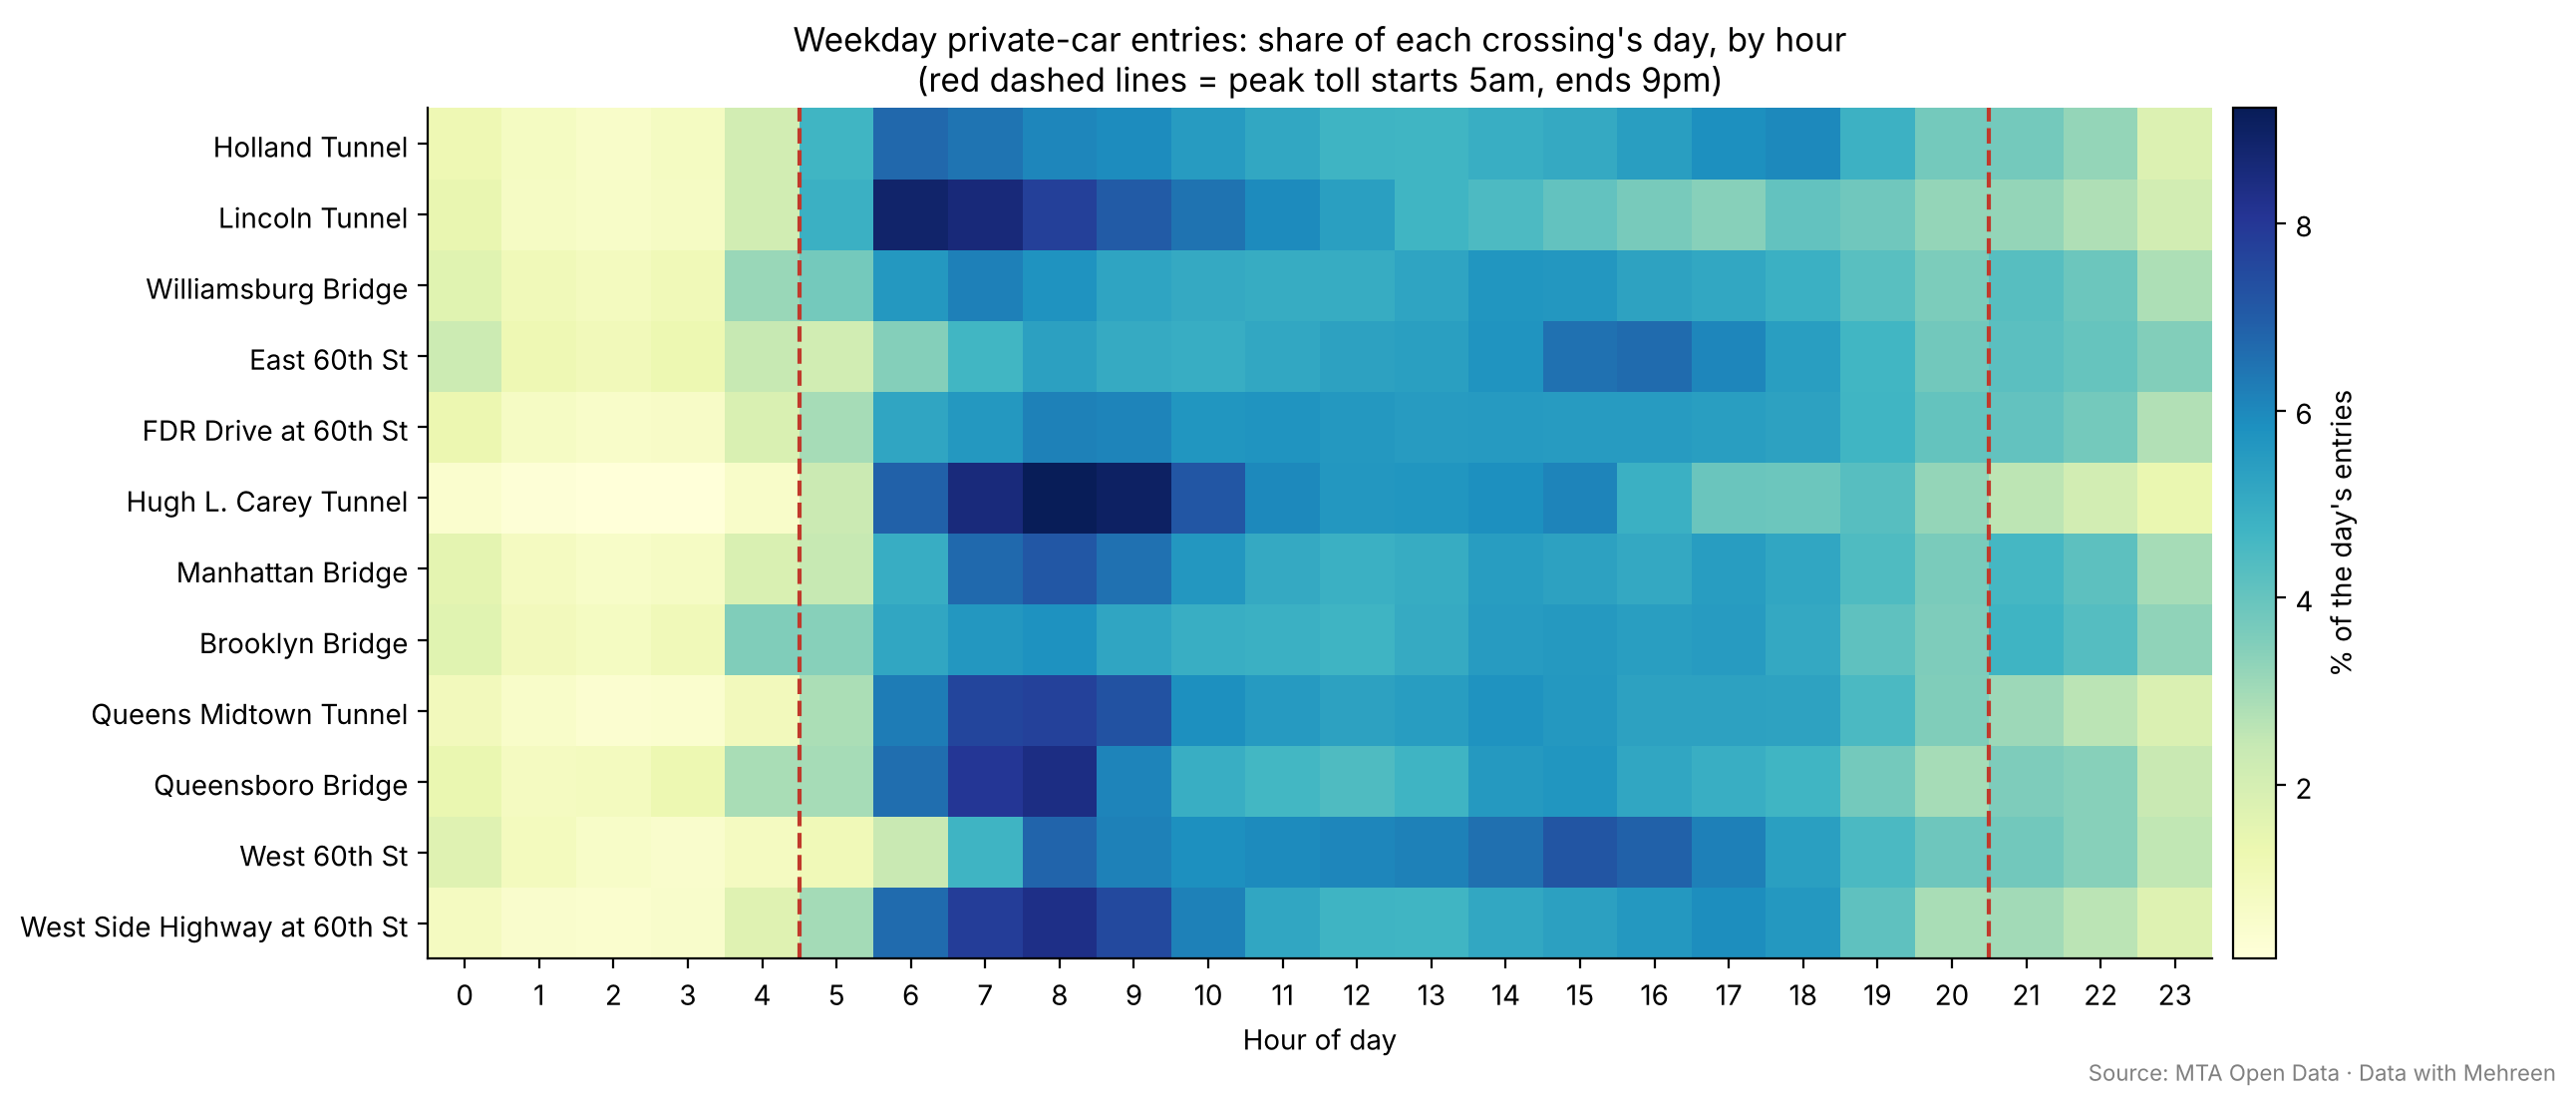

detection_group
East 60th St                    8.1
Brooklyn Bridge                 8.0
Williamsburg Bridge             7.8
Queensboro Bridge               7.2
Lincoln Tunnel                  5.6
Manhattan Bridge                5.6
Holland Tunnel                  5.5
FDR Drive at 60th St            5.1
West 60th St                    4.6
West Side Highway at 60th St    4.0
Queens Midtown Tunnel           3.5
Hugh L. Carey Tunnel            1.6
Name: share_before_5am_%, dtype: float64

In [10]:
wd = crossing_hourly[(crossing_hourly["day_type"] == "Weekday") & (crossing_hourly["vehicle"] == CAR)]
heat = wd.pivot_table(index="detection_group", columns="hour_of_day", values="entries", aggfunc="sum")
heat = heat.div(heat.sum(axis=1), axis=0) * 100
heat = heat.loc[heat.loc[:, 5:11].idxmax(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(13, 5.5))
im = ax.imshow(heat.values, aspect="auto", cmap="YlGnBu")
ax.set_xticks(range(24)); ax.set_xticklabels(range(24))
ax.set_yticks(range(len(heat))); ax.set_yticklabels(heat.index)
ax.axvline(4.5, color="#c0392b", lw=1.5, ls="--")
ax.axvline(20.5, color="#c0392b", lw=1.5, ls="--")
ax.set_xlabel("Hour of day"); ax.grid(False)
ax.set_title("Weekday private-car entries: share of each crossing's day, by hour\n(red dashed lines = peak toll starts 5am, ends 9pm)")
cbar = fig.colorbar(im, ax=ax, pad=0.01); cbar.set_label("% of the day's entries")
add_source(fig); plt.tight_layout(); plt.show()

early = heat.loc[:, 0:4].sum(axis=1).sort_values(ascending=False).round(1).rename("share_before_5am_%")
early

### Q5: Where is toll-timing strongest?
Week 2 found that private car entries **drop ~42%** between 4:50 and 5:00am on weekdays. Is that the same everywhere, or concentrated at a few crossings?

For each crossing: the % change from the last 10 minutes before a toll switch to the first 10 minutes after it.

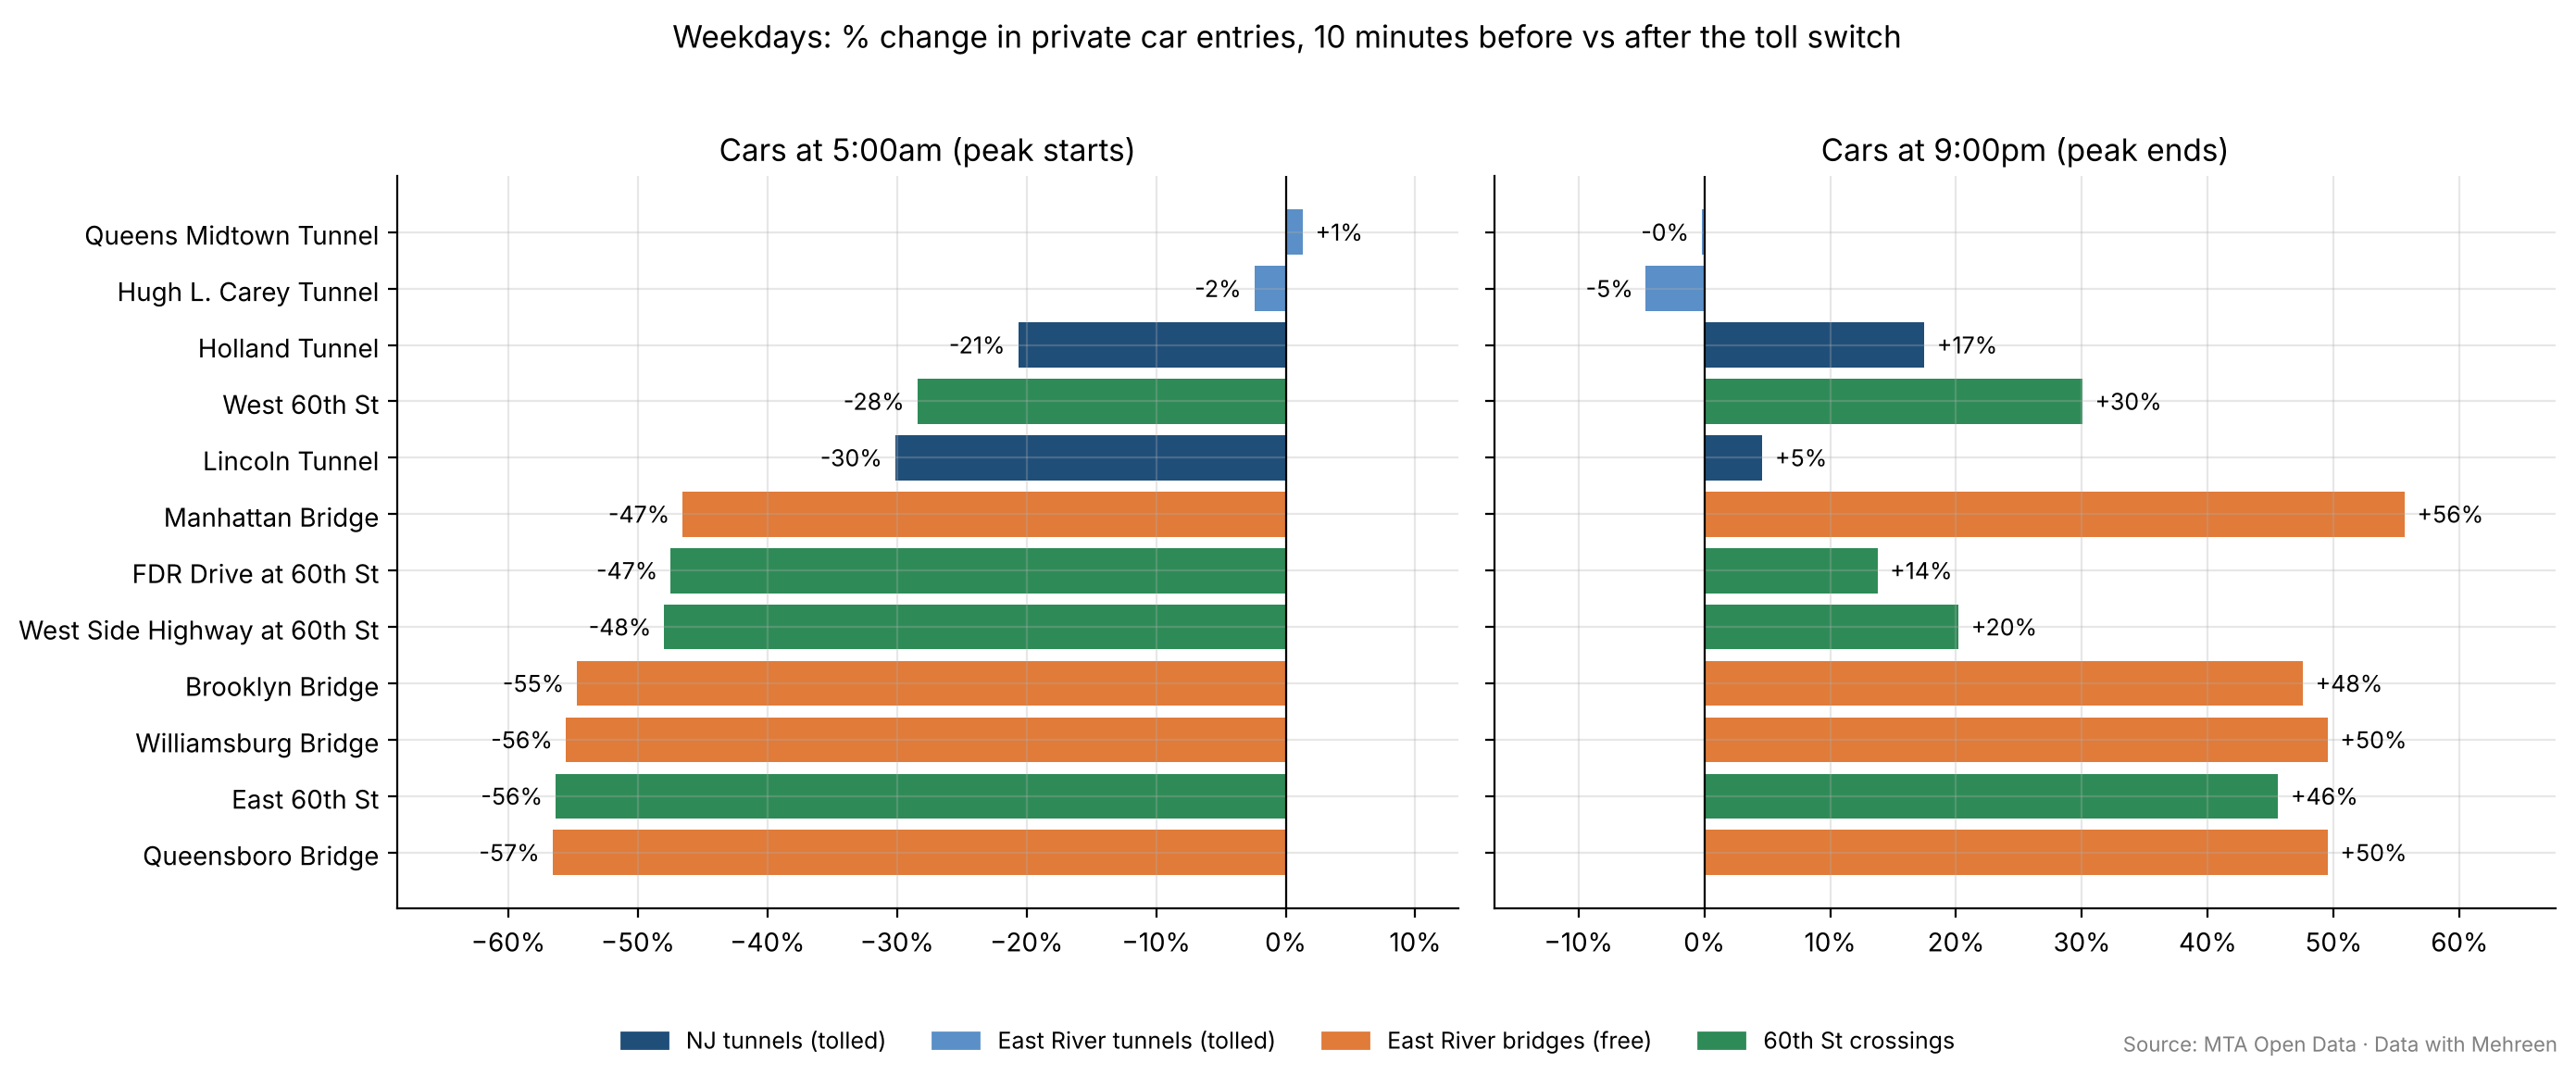

,"Weekday 5:00am, cars","Weekday 5:00am, taxi/FHV","Weekend 9:00am, cars","Weekday 9:00pm, cars"
detection_group,,,,
Queensboro Bridge,-56.6,9.9,-20.6,49.5
East 60th St,-56.3,6.0,-17.3,45.6
Williamsburg Bridge,-55.6,6.1,-22.4,49.5
Brooklyn Bridge,-54.7,-0.9,-19.0,47.6
West Side Highway at 60th St,-48.0,-5.3,-13.3,20.2
FDR Drive at 60th St,-47.5,-4.4,-12.7,13.7
Manhattan Bridge,-46.5,-1.5,-26.9,55.6
Lincoln Tunnel,-30.1,-6.5,-9.9,4.6
West 60th St,-28.4,16.2,-10.3,30.0


In [11]:
def cliff_table(df, day_type, vehicle, boundary_hour):
    sub = df[(df["day_type"] == day_type) & (df["vehicle"] == vehicle)]
    before = sub[(sub["hour_of_day"] == boundary_hour - 1) & (sub["minute_of_hour"] == 50)].groupby("detection_group")["entries"].sum()
    after = sub[(sub["hour_of_day"] == boundary_hour) & (sub["minute_of_hour"] == 0)].groupby("detection_group")["entries"].sum()
    return (after / before - 1) * 100

cliffs = pd.DataFrame({
    "Weekday 5:00am, cars": cliff_table(crossing_boundaries, "Weekday", CAR, 5),
    "Weekday 5:00am, taxi/FHV": cliff_table(crossing_boundaries, "Weekday", TAXI, 5),
    "Weekend 9:00am, cars": cliff_table(crossing_boundaries, "Weekend", CAR, 9),
    "Weekday 9:00pm, cars": cliff_table(crossing_boundaries, "Weekday", CAR, 21),
}).sort_values("Weekday 5:00am, cars")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax, col, title in [(axes[0], "Weekday 5:00am, cars", "Cars at 5:00am (peak starts)"),
                       (axes[1], "Weekday 9:00pm, cars", "Cars at 9:00pm (peak ends)")]:
    vals = cliffs[col]
    ax.barh(cliffs.index, vals, color=[TYPE_COLORS[CROSSING_TYPE[c]] for c in cliffs.index])
    for i, v in enumerate(vals):
        ax.text(v + (1 if v >= 0 else -1), i, f"{v:+.0f}%", va="center", ha="left" if v >= 0 else "right", fontsize=9)
    ax.axvline(0, color="black", lw=0.8)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter())
    lo, hi = vals.min(), vals.max()
    ax.set_xlim(min(lo, 0) - 12, max(hi, 0) + 12)
    ax.set_title(title)
fig.suptitle("Weekdays: % change in private car entries, 10 minutes before vs after the toll switch", y=1.02)
plt.tight_layout(rect=(0, 0.07, 1, 1))
fig.legend(handles=type_legend, frameon=False, loc="lower center", ncol=4, fontsize=9)
add_source(fig); plt.show()
cliffs.round(1)

### Q6: A reader's question: Queensboro Bridge vs. East 60th Street
After my first post, a reader asked:

> *"Could the high concentration of vehicle entries at East 60th Street be influenced by the fact that the 59th Street Bridge has no bridge toll?"*

The Queensboro Bridge (the 59th Street Bridge) is free, and its Manhattan end lands right at the zone's northern edge, next to the East 60th Street crossings. If many Queens drivers come off the bridge and then enter the zone by the East Side streets, we'd expect the two crossings to **move together**: similar hourly patterns, similar vehicle mix, and similar changes over time.

The data can't follow single cars, so this is a test of patterns, not routes.

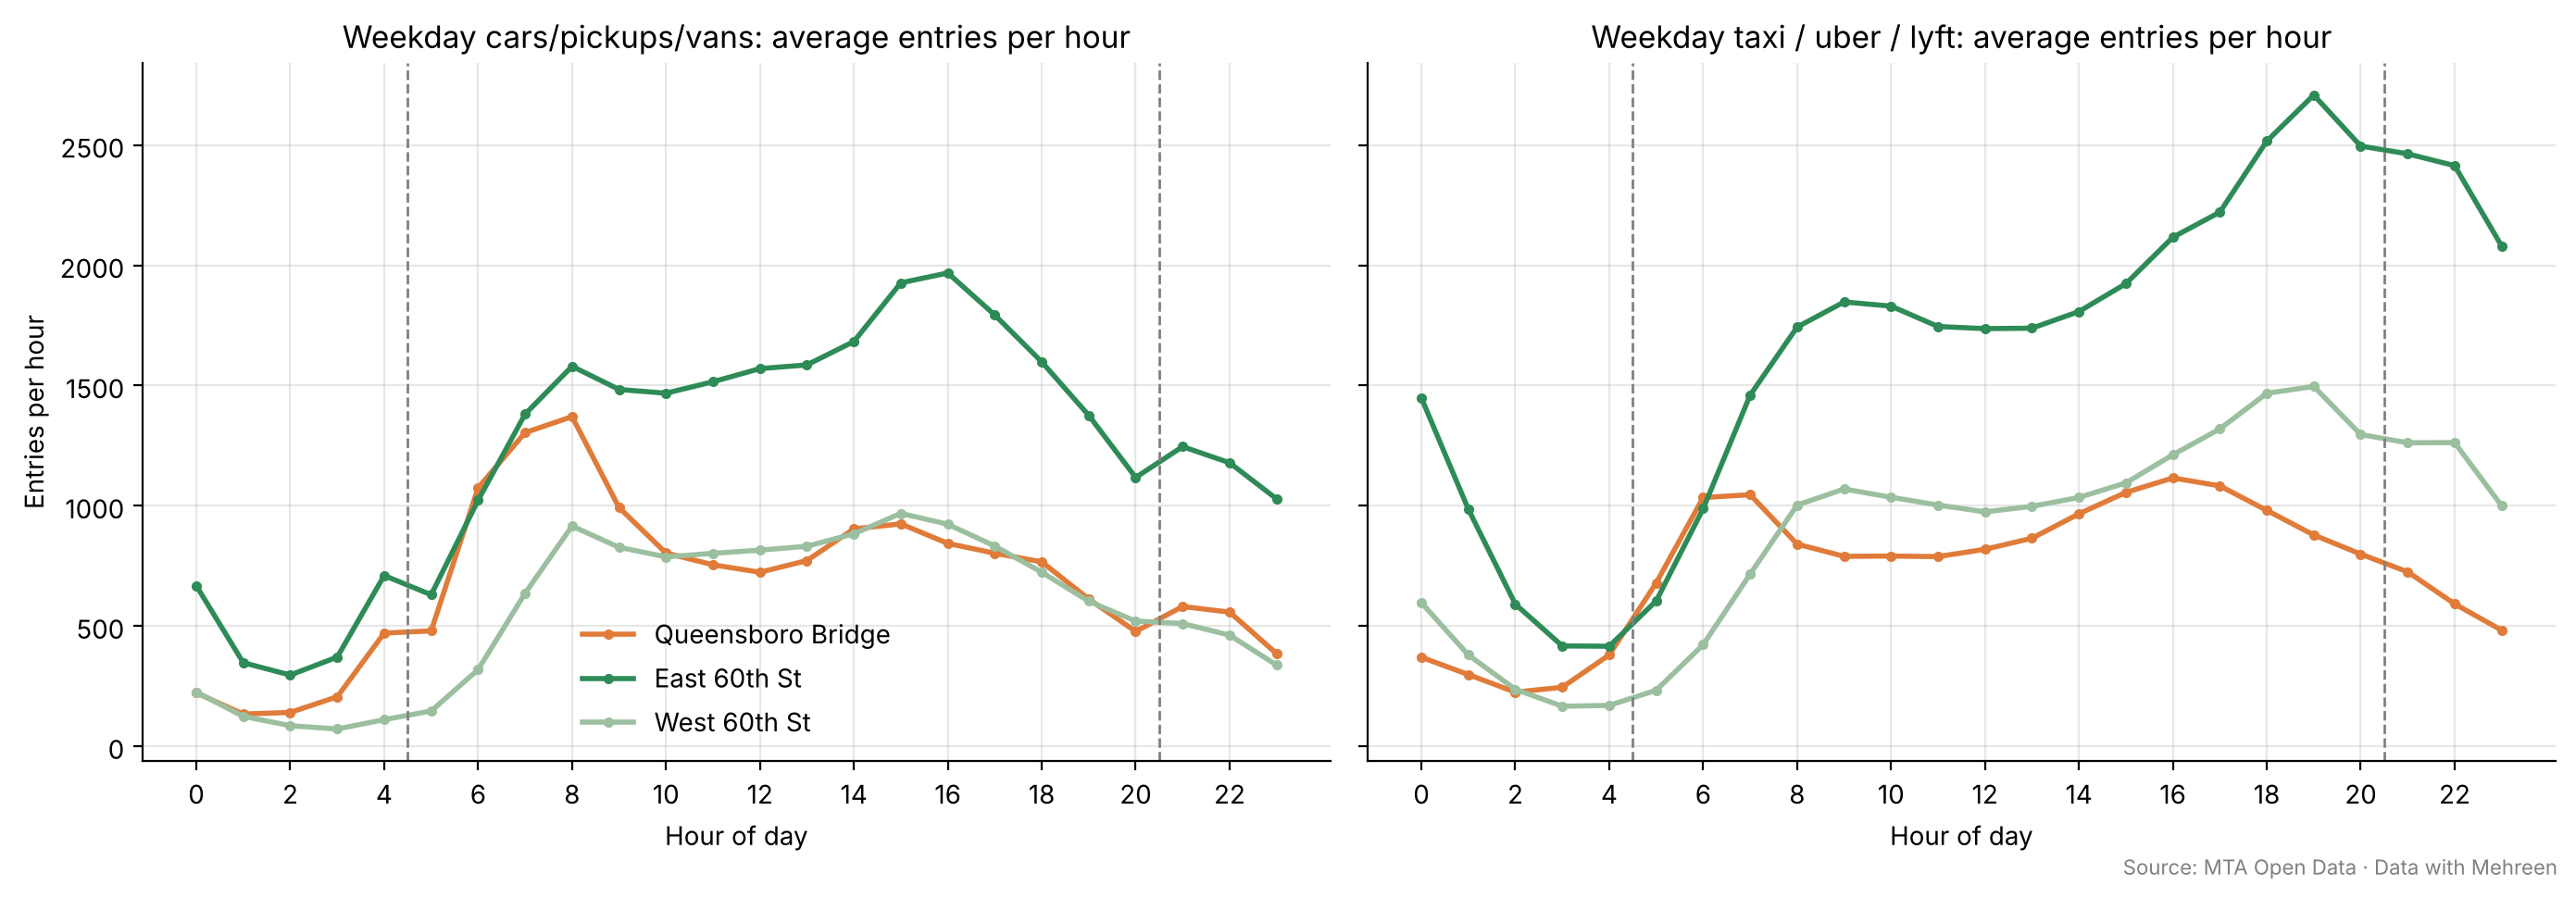

In [12]:
PAIR = ["Queensboro Bridge", "East 60th St", "West 60th St"]
PAIR_COLORS = {"Queensboro Bridge": "#e07b39", "East 60th St": "#2e8b57", "West 60th St": "#9bbf9f"}

h = crossing_hourly[(crossing_hourly["day_type"] == "Weekday") & crossing_hourly["detection_group"].isin(PAIR)]
totals = h.groupby(["detection_group", "hour_of_day", "vehicle"])[["entries", "n_days"]].sum()
per_day = (totals["entries"] / totals["n_days"]).unstack("vehicle")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, vehicle in zip(axes, [CAR, TAXI]):
    for crossing in PAIR:
        s = per_day.loc[crossing, vehicle]
        ax.plot(s.index, s.values, marker="o", ms=3, lw=2, color=PAIR_COLORS[crossing], label=crossing)
    ax.axvline(4.5, color="gray", ls="--", lw=1); ax.axvline(20.5, color="gray", ls="--", lw=1)
    ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("Hour of day")
    ax.set_title(f"Weekday {vehicle.lower()}: average entries per hour")
axes[0].set_ylabel("Entries per hour")
axes[0].legend(frameon=False)
add_source(fig); plt.tight_layout(); plt.show()

In [13]:
# How alike are they? Correlation of the weekday hourly profiles (private cars)
profiles = per_day[CAR].unstack("detection_group")[PAIR]
print("Correlation of weekday hourly car patterns:")
print(profiles.corr().round(2))

# And the vehicle mix and 2025 → 2026 change side by side
summary = pd.DataFrame({
    "avg_daily_entries": volume.reindex(PAIR).round(0),
    "cars_%": mix.loc[PAIR, CAR].round(1),
    "taxi_fhv_%": mix.loc[PAIR, TAXI].round(1),
    "change_2026_vs_2025_%": change.loc[PAIR, "change_%"].round(1),
    "cars_change_%": cv.loc[PAIR, CAR].round(1),
    "taxi_fhv_change_%": cv.loc[PAIR, TAXI].round(1),
})
summary

Correlation of weekday hourly car patterns:
detection_group    Queensboro Bridge  East 60th St  West 60th St
detection_group                                                 
Queensboro Bridge               1.00          0.75          0.75
East 60th St                    0.75          1.00          0.97
West 60th St                    0.75          0.97          1.00


,avg_daily_entries,cars_%,taxi_fhv_%,change_2026_vs_2025_%,cars_change_%,taxi_fhv_change_%
detection_group,,,,,,
Queensboro Bridge,35499.0,44.5,48.3,-4.8,-12.3,3.4
East 60th St,74050.0,38.9,53.8,-6.5,-10.8,-2.5
West 60th St,37119.0,35.1,56.4,-4.7,-6.9,-2.5


## 5. My Week 3 findings ✍️
*Data from Jan 5, 2025 to Nov 7, 2026 (daily tables, storm days removed) and to Nov 14, 2026 (hourly tables).*

1. **Busiest doors:** **East 60th St** carries the most traffic, about **74K entries a day**. Together, the four 60th Street crossings carry **42%** of all entries, more than the free East River bridges (27%), the NJ tunnels (18%) or the East River tunnels (13%).
2. **Biggest drop:** the **Lincoln Tunnel fell 12.3%** from 2025 to 2026. The FDR Drive (−0.5%) and Holland Tunnel (−1.3%) barely changed.
3. **By crossing type:** NJ tunnels **−7.1%**, free East River bridges **−4.8%**, 60th St crossings **−3.8%**, East River tunnels **−3.8%**. The NJ tunnels were down the most in almost every month from May on.
4. **Who drives where:** taxis/Uber/Lyft are the **majority at West 60th St (56%) and East 60th St (54%)**, and almost half at the Queensboro Bridge (48%). Private cars dominate the West Side Highway (73%), Lincoln Tunnel (72%), Hugh L. Carey Tunnel (71%) and Holland Tunnel (70%).
5. **Where private cars fell most:** Brooklyn Bridge and Lincoln Tunnel (**−15% each**), then Queensboro Bridge (−12.3%). Ride-hail grew most at the Holland Tunnel (+10.5%).
6. **Toll-timing is a free-route habit.** At 5:00am on weekdays, private car entries drop **55–57%** at the Queensboro, Williamsburg and Brooklyn bridges and East 60th St. At the tolled **Queens-Midtown and Hugh L. Carey tunnels there is almost no cliff (+1.3% and −2.4%)**, and the NJ tunnels sit in between (−21% and −30%). At 9:00pm the same split appears: free bridges jump **+46% to +56%**, the East River tunnels stay flat. A likely reason: tunnel drivers get a crossing credit at peak, so they save less by timing their trip.
7. **The reader's question:** East 60th St's weekday car pattern matches **West 60th St almost perfectly (correlation 0.97)**, and the Queensboro Bridge less closely (0.75). The bridge peaks at **8am** like a commuter route, while East 60th St peaks around **3–4pm**, with more than half its entries from taxis and ride-hail. So East 60th St looks mostly like a busy city-street entry, not an overflow from the bridge. But both routes are toll-free, and both show the strongest toll-timing of all 12 crossings.

### 📣 Post #3 draft
> A reader asked me a great question: is East 60th Street so busy because the Queensboro Bridge next to it is toll-free? 🌉
>
> So I looked at all 12 entry points into Manhattan's toll zone, one by one.
>
> 🚕 East 60th St is the busiest door (74K a day), but more than half its traffic is taxis and Uber/Lyft.
> 📈 Its hourly pattern matches West 60th St (0.97 correlation), not the bridge. The bridge peaks at 8am; East 60th St peaks mid-afternoon.
> ⏰ But toll-free routes share one habit: at 5:00am, when peak pricing starts, private cars drop **56%** on the free bridges and East 60th St. In the tolled East River tunnels? **Almost no change.**
> 🚇 And the biggest traffic drop of all: the Lincoln Tunnel, **−12%**.
>
> Same toll, 12 very different doors.
>
> Thanks for the question! Full analysis on GitHub (link in comments).
> #DataScience #NYC #CongestionPricing #Python #DataWithMehreen

## Notes and caveats
- The data counts where a vehicle is **first detected** entering the zone, not where it came from or the route it took. A correlation of hourly patterns is evidence, not proof, about where traffic comes from.
- A crossing's change can reflect construction, lane closures or events, not only the toll.
- The hourly and boundary tables include storm days, holidays and the newest partial week; the daily tables exclude them.